## 0. Setup Awal

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

OUTPUT_DIR = 'outputLogisticRegressionComparison'
os.makedirs(OUTPUT_DIR, exist_ok=True)
plt.rcParams['figure.dpi'] = 120

## 1. Data Understanding

### 1.1 Load Hasil Evaluasi

In [2]:
files = {
    'L1': 'outputLogisticRegressionL1AntiBurnout/metrics_logistic_regression_l1.csv',
    'L2': 'outputLogisticRegressionL2AntiBurnout/metrics_logistic_regression_l2.csv',
    'Elastic Net': 'outputLogisticRegressionElastic_NetAntiBurnout/metrics_logistic_regression_elastic_net.csv'
}

results = []
for name, path in files.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f'File hasil {name} belum ditemukan: {path}')
    data = pd.read_csv(path)
    data['Regularization'] = name
    results.append(data)

df_comparison = pd.concat(results, ignore_index=True)
display(df_comparison)

,Model,Feature_Count,Excluded_Feature,Penalty,L1_Ratio,C,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB,Regularization
0,Logistic Regression L1,30,Mental_Health_Status,l1,NaN,0.01,0.8160,0.8005,0.7950,0.7974,0.8172,0.8150,0.7961,96.9798,40.5254,L1
1,Logistic Regression L2,30,Mental_Health_Status,l2,NaN,0.10,0.8167,0.8005,0.7965,0.7982,0.8178,0.8143,0.7950,56.4391,40.5295,L2
2,Logistic Regression Elastic Net,30,Mental_Health_Status,elasticnet,0.75,0.01,0.8163,0.8008,0.7955,0.7976,0.8177,0.8147,0.7959,214.2773,40.6447,Elastic Net


## 2. Preprocessing

### 2.1 Penyusunan Tabel Perbandingan

In [3]:
metric_columns = [
    'Accuracy', 'Precision_Macro', 'Recall_Macro',
    'F1_Score_Macro', 'F1_Score_Weighted'
]

display(df_comparison[['Regularization'] + metric_columns])

,Regularization,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted
0,L1,0.8160,0.8005,0.7950,0.7974,0.8172
1,L2,0.8167,0.8005,0.7965,0.7982,0.8178
2,Elastic Net,0.8163,0.8008,0.7955,0.7976,0.8177


## 3. Modeling

### 3.1 Perbandingan Metrik Evaluasi

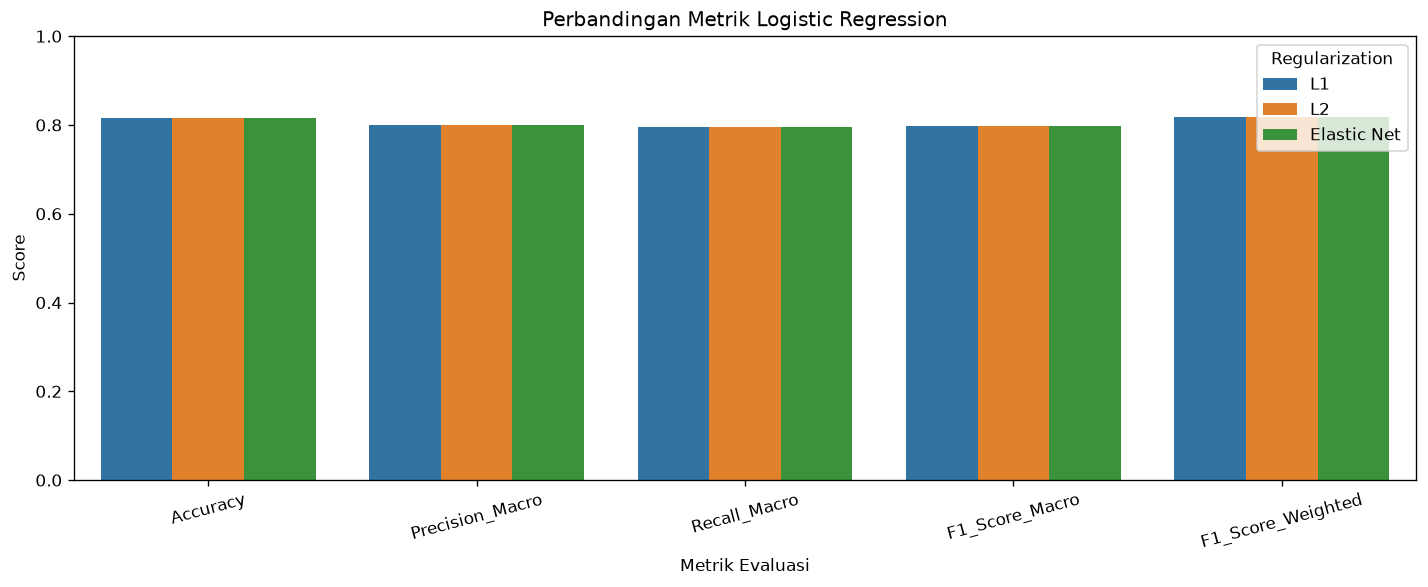

In [4]:
plot_data = df_comparison.melt(
    id_vars='Regularization',
    value_vars=metric_columns,
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_data, x='Metric', y='Score', hue='Regularization')
plt.title('Perbandingan Metrik Logistic Regression')
plt.ylabel('Score')
plt.xlabel('Metrik Evaluasi')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 4. Evaluasi

### 4.1 Perbandingan Stratified 5-Fold Cross-Validation

In [5]:
cv_files = {
    'L1': 'outputLogisticRegressionL1AntiBurnout/cv_5fold_logistic_regression_l1.csv',
    'L2': 'outputLogisticRegressionL2AntiBurnout/cv_5fold_logistic_regression_l2.csv',
    'Elastic Net': 'outputLogisticRegressionElastic_NetAntiBurnout/cv_5fold_logistic_regression_elastic_net.csv'
}

cv_frames = []
for name, path in cv_files.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f'File CV {name} belum ditemukan: {path}')
    data = pd.read_csv(path)
    data['Regularization'] = name
    cv_frames.append(data)

df_cv_comparison = pd.concat(cv_frames, ignore_index=True)
display(df_cv_comparison)

,Fold,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted),Regularization
0,Fold 1,0.814625,0.802356,0.789837,0.794890,0.816095,L1
1,Fold 2,0.819375,0.806282,0.794415,0.799649,0.819924,L1
2,Fold 3,0.817250,0.807603,0.794666,0.800148,0.818398,L1
3,Fold 4,0.810500,0.798201,0.786068,0.790994,0.812030,L1
4,Fold 5,0.813250,0.802720,0.788824,0.794875,0.813961,L1
5,Mean,0.815000,0.803432,0.790762,0.796111,0.816081,L1
6,Std,0.003087,0.003303,0.003324,0.003406,0.002865,L1
7,Fold 1,0.814750,0.800776,0.791436,0.795327,0.816089,L2
8,Fold 2,0.819875,0.805084,0.796085,0.800216,0.820150,L2
9,Fold 3,0.815875,0.802800,0.793527,0.797622,0.816747,L2


### 4.2 Ringkasan Waktu Eksekusi dan Penggunaan Memori

In [6]:
display(df_comparison[[
    'Regularization', 'C', 'L1_Ratio', 'Training_Time_s', 'Peak_Memory_MB'
]])

,Regularization,C,L1_Ratio,Training_Time_s,Peak_Memory_MB
0,L1,0.01,NaN,96.9798,40.5254
1,L2,0.10,NaN,56.4391,40.5295
2,Elastic Net,0.01,0.75,214.2773,40.6447


## 5. Visualisasi Hasil

### 5.1 Visualisasi Metrik Evaluasi

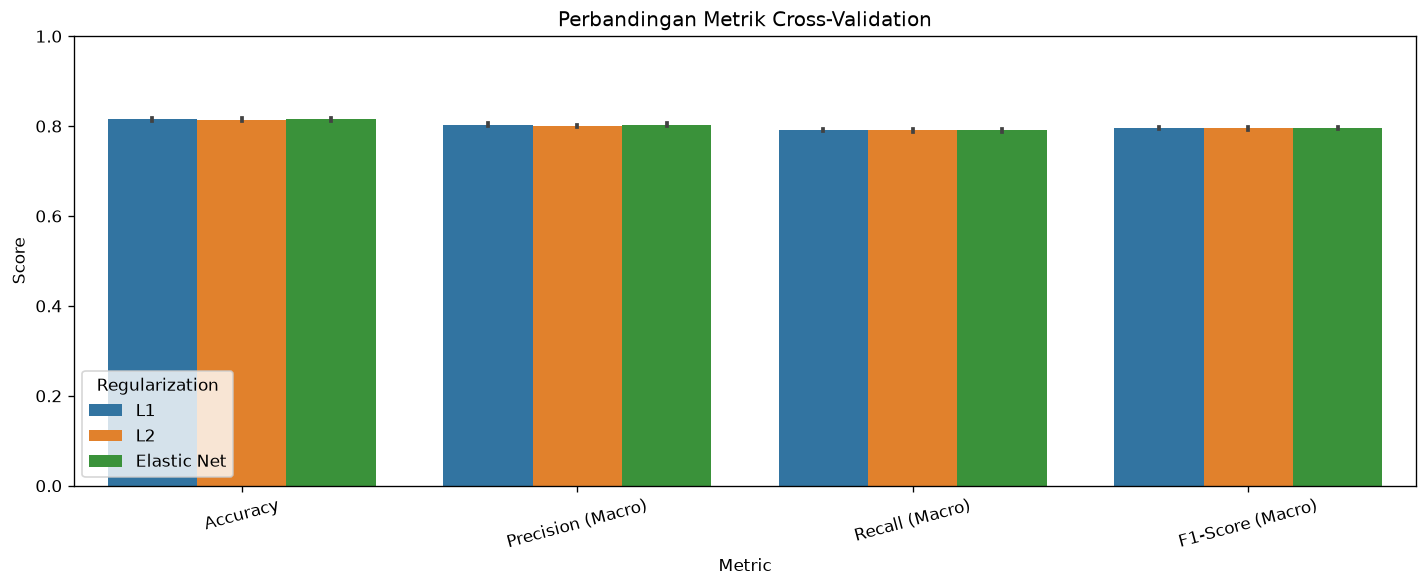

In [7]:
cv_metric_columns = [
    'Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'
]

cv_summary = df_cv_comparison[df_cv_comparison['Fold'].isin([f'Fold {i}' for i in range(1, 6)])]
cv_long = cv_summary.melt(
    id_vars=['Fold', 'Regularization'],
    value_vars=cv_metric_columns,
    var_name='Metric', value_name='Score'
)

plt.figure(figsize=(12, 5))
sns.barplot(data=cv_long, x='Metric', y='Score', hue='Regularization')
plt.title('Perbandingan Metrik Cross-Validation')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 6. Analisis

### 6.1 Penentuan Model Terbaik

In [8]:
best_model = df_comparison.sort_values(
    by='F1_Score_Macro', ascending=False
).iloc[0]

print('Model dengan F1-Score Macro tertinggi:')
print(best_model[['Regularization', 'F1_Score_Macro', 'Accuracy', 'C', 'L1_Ratio']])

Model dengan F1-Score Macro tertinggi:
Regularization        L2
F1_Score_Macro    0.7982
Accuracy          0.8167
C                    0.1
L1_Ratio             NaN
Name: 1, dtype: object


## 7. Ekspor File

### 7.1 Ekspor Ringkasan Evaluasi

In [9]:
df_comparison.to_csv(
    f'{OUTPUT_DIR}/comparison_metrics.csv', index=False
)
df_cv_comparison.to_csv(
    f'{OUTPUT_DIR}/comparison_cv_5fold.csv', index=False
)
print('File perbandingan berhasil disimpan.')

File perbandingan berhasil disimpan.
